# Rabbits and foxes, by kinetic Monte Carlo

**CHME 5137, Lecture 10, Tuesday October 13, 2026.** Started in class, finished for
homework.

*Written for 2026 by Claude Code (Claude Opus 5.5) from Prof. West's KMC question of
earlier years, and checked by Prof. West. The problem is from Chapter 1 of H. Scott
Fogler's "Essentials of Chemical Reaction Engineering".*

---

Same farm, same rate constants: 400 rabbits and 200 foxes at the start, and

$$\frac{dR}{dt} = k_1 R - k_2 R F \qquad\qquad \frac{dF}{dt} = k_3 R F - k_4 F$$

with $k_1 = 0.015$ day$^{-1}$, $k_2 = 0.00004$ day$^{-1}$ foxes$^{-1}$,
$k_3 = 0.0004$ day$^{-1}$ rabbits$^{-1}$ and $k_4 = 0.04$ day$^{-1}$.

In the `solve_ivp` homework you found that the foxes fall to **under two** in each
trough. The ODEs don't mind: 1.6 foxes carry on and breed. Real foxes can't be
fractional, and two foxes can easily both die before they meet a rabbit. So now we
treat every rabbit and fox as an individual, and every birth and death as a random
event. That is **kinetic Monte Carlo** (KMC).

### The events

There are four events. Each has a rate, in events per day, which changes as the
populations change:

| Event | Rate | Effect |
|---|---|---|
| a rabbit is born | $k_1 R$ | $R \to R + 1$ |
| a rabbit is eaten | $k_2 R F$ | $R \to R - 1$ |
| a fox is born | $k_3 R F$ | $F \to F + 1$ |
| a fox dies | $k_4 F$ | $F \to F - 1$ |

The rates are easy to calculate, so we use the **rejection-free** algorithm, which you
worked out in class from
[Wikipedia's Kinetic Monte Carlo page](https://en.wikipedia.org/wiki/Kinetic_Monte_Carlo).
Writing it down in your own words is the first part of task 1.

### How to work

- **Commit as you go.** After each numbered task works, Restart & Run All, then
  stage, commit with a message that says what you did, and push. At least one commit
  per task. Your commit history is part of what gets looked at. **Commit the `.ipynb`
  and its paired `.py` together**: the `.py` is the one whose diffs you can read on
  GitHub. If saving the notebook doesn't update the `.py`, see *Setting up Jupytext* on
  Canvas.
- **Answer the questions in words**, in the markdown cells marked *Answer*.
  Double-click a cell to edit it.
- **Random numbers:** use a NumPy generator, `rng = np.random.default_rng(seed)`,
  not the legacy `np.random.*` functions. Give it a seed, so that Restart & Run All
  gives the same answers every time. Check what interval each function returns,
  and what its arguments mean, before you trust it.
- **Let bugs shout.** If a population goes negative or an event isn't one of the
  four, `raise` an error. Don't hide it with `max(0, F)`: that turns a bug you'd
  notice into a wrong answer you won't.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

k1 = 0.015  # 1/day
k2 = 0.00004  # 1/day/fox
k3 = 0.0004  # 1/day/rabbit
k4 = 0.04  # 1/day

R0, F0 = 400, 200  # rabbits and foxes at t = 0
t_end = 600  # days

The deterministic answer, for comparison. This is the `solve_ivp` homework's
solution, at a tight tolerance.

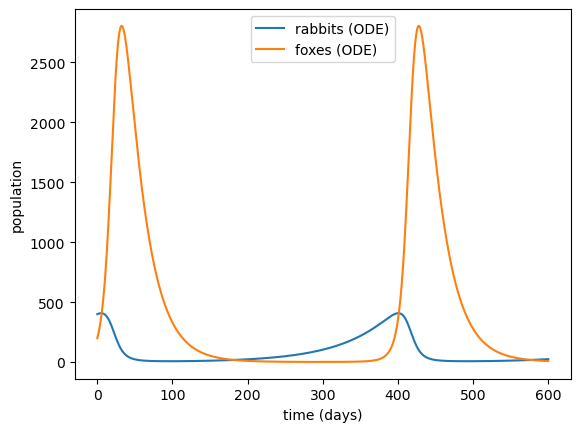

In [2]:
def dydt(t, y):
    R, F = y
    return [k1 * R - k2 * R * F, k3 * R * F - k4 * F]

ode = solve_ivp(dydt, (0, t_end), [R0, F0], rtol=1e-10, atol=1e-8, dense_output=True)
t_ode = np.linspace(0, t_end, 3001)
R_ode, F_ode = ode.sol(t_ode)

plt.plot(t_ode, R_ode, label="rabbits (ODE)")
plt.plot(t_ode, F_ode, label="foxes (ODE)")
plt.xlabel("time (days)")
plt.ylabel("population")
plt.legend()
plt.show()

## 1. One trajectory

**(a) The algorithm, in your own words.** Before you write any code, write the
rejection-free algorithm as numbered steps, for rabbits and foxes: what each of
Wikipedia's symbols ($k$, $r_{ki}$, $R_{ki}$, $Q_k$, $u$, $u'$) becomes here, how the
next event is chosen, and how far the clock moves. Then work the **first step by
hand**, from 400 rabbits and 200 foxes, with $u = 0.5$ and $u' = 0.3$: which event
happens, and how many minutes pass?

*Answer:*

**Wikipedia's symbols, for rabbits and foxes**

| Symbol | Here |
|---|---|
| $k$ | the current state, i.e. the numbers of rabbits and foxes $(R, F)$ |
| $r_{ki}$ | the rate of event $i$ in that state: $r_1 = k_1 R$, $r_2 = k_2 R F$, $r_3 = k_3 R F$, $r_4 = k_4 F$ (events/day) |
| $R_{ki}$ | the cumulative rate $R_{ki} = \sum_{j \le i} r_{kj}$, so $R_{k4} = Q_k$ |
| $Q_k$ | the total rate of all four events, $Q_k = r_1 + r_2 + r_3 + r_4$ |
| $u$ | a uniform random number in $(0, 1]$, used to **choose which event** happens |
| $u'$ | a second, independent uniform random number in $(0, 1]$, used to **choose how long** it takes |

**The algorithm**

1. Set $t = 0$, $R = 400$, $F = 200$.
2. Calculate the four rates $r_1 \ldots r_4$ from the current $R$ and $F$.
3. Form the cumulative rates $R_{k1}, R_{k2}, R_{k3}, R_{k4} = Q_k$. If $Q_k = 0$,
   nothing can happen, so stop.
4. Draw $u$ and pick the event $i$ with $R_{k,i-1} < u Q_k \le R_{ki}$. Each event is
   chosen with probability $r_{ki} / Q_k$.
5. Carry out that event: $R \pm 1$ or $F \pm 1$.
6. Draw $u'$ and move the clock on by $\Delta t = -\ln(u') / Q_k$. This is an exponentially
   distributed waiting time with mean $1/Q_k$.
7. Record $(t, R, F)$, and go back to step 2 until $t$ passes $t_\text{end}$.

**The first step by hand** ($R = 400$, $F = 200$, $u = 0.5$, $u' = 0.3$)

| $i$ | event | $r_i$ (1/day) | $R_{ki}$ (1/day) |
|---|---|---|---|
| 1 | rabbit born | $0.015 \times 400 = 6$ | 6 |
| 2 | rabbit eaten | $0.00004 \times 400 \times 200 = 3.2$ | 9.2 |
| 3 | fox born | $0.0004 \times 400 \times 200 = 32$ | 41.2 |
| 4 | fox dies | $0.04 \times 200 = 8$ | 49.2 |

$Q = 49.2$ events/day, and $uQ = 0.5 \times 49.2 = 24.6$. This falls between
$R_{k2} = 9.2$ and $R_{k3} = 41.2$, so **a fox is born**: $R = 400$, $F = 201$.

$$\Delta t = \frac{-\ln(0.3)}{49.2} = \frac{1.204}{49.2} = 0.02447 \text{ days}
= 0.02447 \times 1440 \approx \mathbf{35.2 \text{ minutes}}$$

**(b) The function.** Write

```python
def kmc(R0, F0, t_end, rng):
    ...
    return times, rabbits, foxes   # three NumPy arrays, one entry per event
```

that runs your algorithm from $t = 0$ until the clock passes `t_end`. If the total
rate is ever zero, nothing more can happen, so stop there.

Run it once. How many events were there, and how long did it take? Plot rabbits and
foxes against time, on top of the ODE solution. (`plt.step(times, foxes, where="post")`
draws a population that jumps, rather than one that slopes.) Run it a few more times
with different seeds. How does a KMC trajectory differ from the ODE solution?

24813 events in 0.09 s
at t = 602.4 days: 24 rabbits, 1 foxes


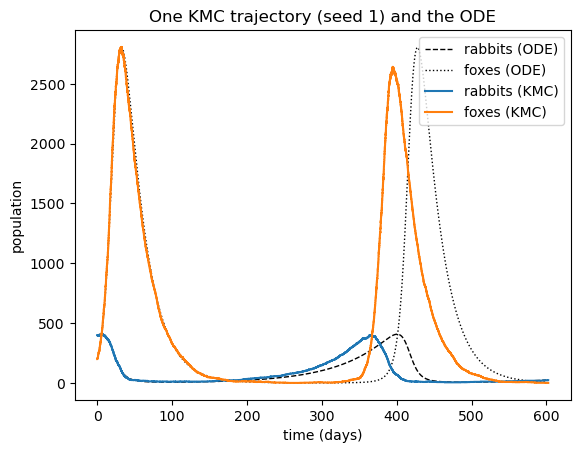

In [3]:
def kmc(R0, F0, t_end, rng):
    """One rejection-free KMC trajectory, from t = 0 until the clock passes t_end.

    Returns times, rabbits, foxes: NumPy arrays with one entry for the start and
    one per event.
    """
    R, F, t = R0, F0, 0.0
    times, rabbits, foxes = [t], [R], [F]
    while t < t_end:
        rates = np.array([k1 * R, k2 * R * F, k3 * R * F, k4 * F])  # r_ki, events/day
        cumulative = np.cumsum(rates)  # R_ki
        Q = cumulative[-1]  # Q_k
        if Q == 0:
            break  # no rabbits and no foxes, so nothing can ever happen again

        # rng.random() is in [0, 1). 1 - rng.random() is in (0, 1], so u > 0 never picks
        # an event with zero rate, and log(u_prime) is always finite.
        u = 1.0 - rng.random()
        u_prime = 1.0 - rng.random()

        i = np.searchsorted(cumulative, u * Q)  # first i with R_ki >= u Q
        if i == 0:
            R += 1  # a rabbit is born
        elif i == 1:
            R -= 1  # a rabbit is eaten
        elif i == 2:
            F += 1  # a fox is born
        elif i == 3:
            F -= 1  # a fox dies
        else:
            raise RuntimeError(f"event index {i} is not one of the four events")
        if R < 0 or F < 0:
            raise RuntimeError(f"negative population at t = {t}: R = {R}, F = {F}")

        t += -np.log(u_prime) / Q
        times.append(t)
        rabbits.append(R)
        foxes.append(F)
    return np.array(times), np.array(rabbits), np.array(foxes)


rng = np.random.default_rng(1)
start = time.perf_counter()
times, rabbits, foxes = kmc(R0, F0, t_end, rng)
elapsed = time.perf_counter() - start
print(f"{len(times) - 1} events in {elapsed:.2f} s")
print(f"at t = {times[-1]:.1f} days: {rabbits[-1]} rabbits, {foxes[-1]} foxes")

plt.plot(t_ode, R_ode, "k--", lw=1, label="rabbits (ODE)")
plt.plot(t_ode, F_ode, "k:", lw=1, label="foxes (ODE)")
plt.step(times, rabbits, where="post", label="rabbits (KMC)")
plt.step(times, foxes, where="post", label="foxes (KMC)")
plt.xlabel("time (days)")
plt.ylabel("population")
plt.title("One KMC trajectory (seed 1) and the ODE")
plt.legend()
plt.show()

The same thing with four other seeds, with the populations on a log scale so the
troughs show up.

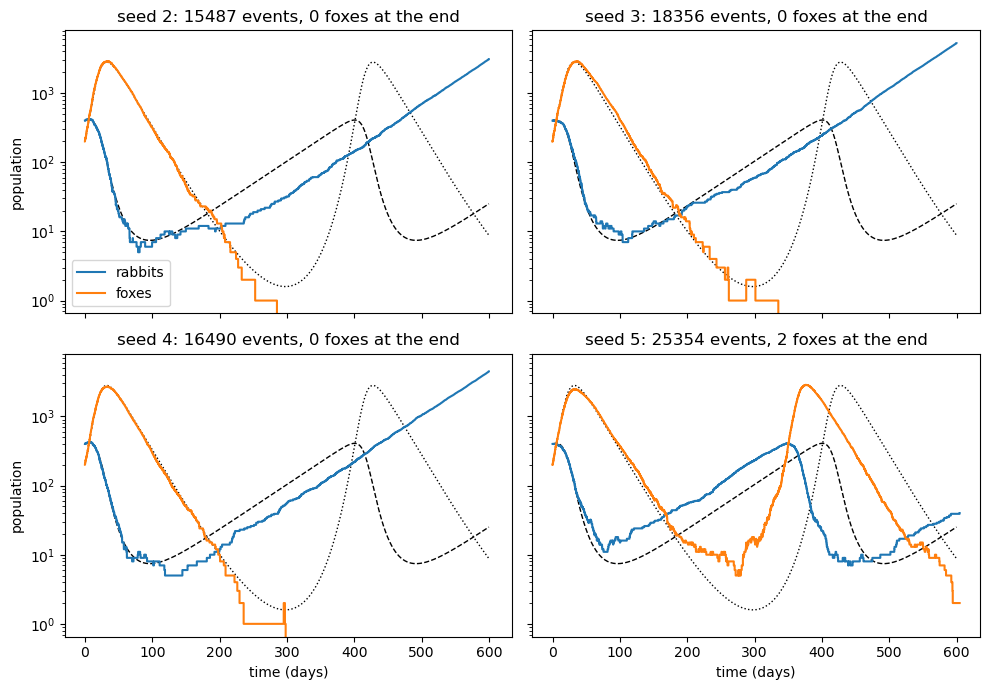

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharex=True, sharey=True)
for seed, ax in zip([2, 3, 4, 5], axes.flat):
    times, rabbits, foxes = kmc(R0, F0, t_end, np.random.default_rng(seed))
    ax.plot(t_ode, R_ode, "k--", lw=1)
    ax.plot(t_ode, F_ode, "k:", lw=1)
    ax.step(times, rabbits, where="post", label="rabbits")
    ax.step(times, foxes, where="post", label="foxes")
    ax.set_yscale("log")
    ax.set_title(f"seed {seed}: {len(times) - 1} events, {foxes[-1]} foxes at the end")
axes[0, 0].legend()
for ax in axes[1]:
    ax.set_xlabel("time (days)")
for ax in axes[:, 0]:
    ax.set_ylabel("population")
plt.tight_layout()
plt.show()

*Answer:*

With seed 1 there were **24,813 events**, which took about **0.1 s**. The clock
finished at day 602.4, just past `t_end`, with 24 rabbits and 1 fox left. Runs where
the foxes die out have fewer events (about 15,000–18,000), because there is no second
fox boom.

How a KMC trajectory differs from the ODE:

- **The populations are whole numbers that jump**, and they jitter around the ODE
  curve instead of following it smoothly. While populations are in the thousands
  (the first fox peak, around day 32) the jitter is relatively small and every run
  follows the ODE closely. The relative noise grows like $1/\sqrt{N}$, so it matters
  most in the troughs.
- **The foxes can die out.** The ODE's foxes go down to 1.6 at day 298 and come back.
  In seeds 2, 3 and 4 the KMC foxes reach zero between days 240 and 300 and never come
  back. The rabbits then grow exponentially at rate $k_1$ (a straight line on the log
  plot), to thousands by day 600, with no second cycle.
- **Even when the foxes survive, the timing drifts.** Seed 1 got down to a single
  fox at day 255 and survived by luck. Seed 5 bottomed out at 5 foxes. In both, the
  rabbits recovered a little ahead of the ODE, so the second fox peak came around day
  375–395, well before the ODE's day 428, and it was lower. Small random
  differences in the trough turn into large differences in the phase of the next
  cycle.

## 2. Many trajectories, and where they end up

Plot the foxes from 20 trajectories on one graph (thin lines, `lw=0.5`), with the ODE
solution on top.

- What do the trajectories have in common, and where do they spread apart?
- What happens to a trajectory once the foxes reach zero? Once the rabbits reach
  zero? Why can't it ever recover?
- Where in the cycle do the foxes usually die out, and why there? (Your answer to
  task 5 of the `solve_ivp` homework is relevant.)

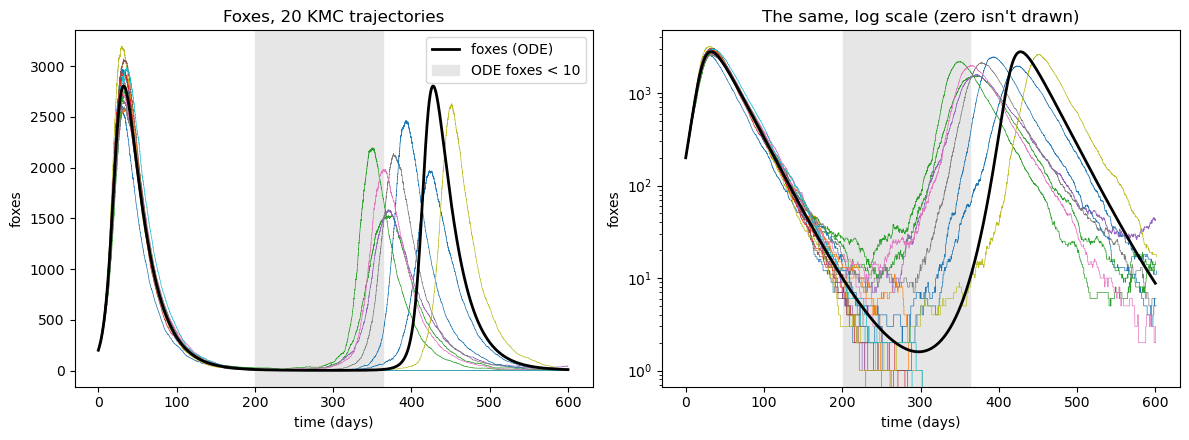

ODE fox trough: 1.59 foxes at day 298
ODE rabbits = k4/k3 = 100 at day 298

run  foxes die out at  rabbits then  rabbits at the end
  0  survive (12 foxes at day 600)          69
  1  day 302.0          168          15224
  2  survive (14 foxes at day 600)          106
  3  day 271.1           67          11485
  4  survive (42 foxes at day 600)          139
  5  day 265.4           51          6797
  6  day 261.2           53          11157
  7  survive (6 foxes at day 600)          100
  8  day 261.1           47          7577
  9  day 289.2           62          6300
 10  survive (5 foxes at day 600)          52
 11  day 263.1           47          6823
 12  survive (15 foxes at day 600)          157
 13  day 280.1           62          7351
 14  day 230.0           46          11538
 15  day 283.2           49          6296
 16  survive (3 foxes at day 600)          139
 17  day 250.0           55          10526
 18  survive (17 foxes at day 600)          14
 19  day 302.6         

In [5]:
rng = np.random.default_rng(2026)
trajectories = [kmc(R0, F0, t_end, rng) for _ in range(20)]

fig, (ax_lin, ax_log) = plt.subplots(1, 2, figsize=(12, 4.5))
for ax in (ax_lin, ax_log):
    for times, rabbits, foxes in trajectories:
        ax.step(times, foxes, where="post", lw=0.5)
    ax.plot(t_ode, F_ode, "k", lw=2, label="foxes (ODE)")
    ax.axvspan(*t_ode[(F_ode < 10) & (t_ode < 400)][[0, -1]], color="0.9", zorder=0,
               label="ODE foxes < 10")
    ax.set_xlabel("time (days)")
    ax.set_ylabel("foxes")
ax_log.set_yscale("log")
ax_lin.set_title("Foxes, 20 KMC trajectories")
ax_log.set_title("The same, log scale (zero isn't drawn)")
ax_lin.legend()
plt.tight_layout()
plt.show()

print(f"ODE fox trough: {F_ode[t_ode < 400].min():.2f} foxes "
      f"at day {t_ode[t_ode < 400][F_ode[t_ode < 400].argmin()]:.0f}")
print(f"ODE rabbits = k4/k3 = {k4 / k3:.0f} at day "
      f"{t_ode[(t_ode > 200) & (R_ode > k4 / k3)][0]:.0f}")
print("\nrun  foxes die out at  rabbits then  rabbits at the end")
for n, (times, rabbits, foxes) in enumerate(trajectories):
    if (rabbits == 0).any():
        raise RuntimeError(f"run {n}: the rabbits died out; handle this case")
    if foxes[-1] == 0:
        i = np.argmax(foxes == 0)
        print(f"{n:3d}  day {times[i]:5.1f}         {rabbits[i]:4d}          {rabbits[-1]}")
    else:
        print(f"{n:3d}  survive ({foxes[-1]} foxes at day {t_end})          {rabbits[-1]}")
n_extinct = sum(foxes[-1] == 0 for _, _, foxes in trajectories)
print(f"\nfoxes died out in {n_extinct} of {len(trajectories)} runs")

*Answer:*

**What they have in common, and where they spread apart.** All 20 trajectories
follow the ODE closely through the first fox peak, about 2,600–3,200 foxes at around
day 32, and down the decline to about day 150. Fox numbers are in the hundreds or
thousands there, so one birth or death hardly matters and the law of large numbers
makes the KMC behave like the ODE. They spread apart in the **trough** (the grey band,
where the ODE has fewer than 10 foxes). There each event is a sizeable fraction of
the population. Some runs go to zero, and the rest come out of the trough at
different times, so their second peaks are spread from about day 345 to 450 and from
about 1,500 to 2,600 foxes. Most come earlier and lower than the ODE's peak at day 428.

**Once the foxes reach zero**, the fox-birth rate $k_3 R F$ is zero, because new foxes
can only come from existing foxes. So $F$ stays at 0 forever. The only event left is
rabbit birth, so the rabbits grow exponentially as $e^{k_1 t}$, to thousands by day
600. **If the rabbits reached zero**, rabbit births ($k_1 R$) and fox births
($k_3 R F$) would both stop. The only event left would be fox deaths at $k_4 F$, so the
foxes would starve to extinction and the farm would end empty at $Q = 0$. That's
where the `Q == 0` stop in `kmc` comes in. (It didn't happen in these 20 runs.
The rabbits' lowest point, about 7 in the ODE, comes around day 490, so it is only
possible in runs that get to the second cycle.) Zero is an **absorbing state** for
each species. Every event that could create an animal has a rate proportional to the
number of that animal, so nothing can bring a species back from zero. The ODE never
reaches zero: there $F$ decays like $e^{-\text{rate}\, t}$, and 1.6 foxes can still breed.

**Where in the cycle the foxes die out.** In 12 of the 20 runs the foxes died out,
all between **day 230 and day 303**. That is the falling side of the trough, just
before the ODE's minimum of 1.6 foxes at day 298. The reason is the per-fox balance
of births and deaths. A fox is born at rate $k_3 R$ per fox and dies at rate $k_4$, so
the foxes shrink on average whenever $R < k_4 / k_3 = 100$ rabbits. In the ODE the
rabbits only climb back past 100 at about day 298, exactly where the fox curve turns
around (task 5 of the `solve_ivp` homework). Until then, each fox is more likely to die
than to breed: at day 230 there are about 37 rabbits, so births are only 37% as likely
as deaths. The foxes are down to a handful at exactly the time when every one is more
likely to die than to reproduce, which is the most dangerous combination. The rabbits
when the last fox died were mostly 45–70, below 100. In run 19 the rabbits lagged
behind (still about 20 at day 300), so its dangerous stretch lasted longer. Run 1 had
168 rabbits but was down to its last fox, which can die before it breeds even when the
odds favour breeding. Once $R > 100$ the foxes grow on average, and the runs that made
it that far went on to a second peak.

## 3. The second fox peak

The ODE's foxes peak at about day 32, and again at about day 428, at about 2804
foxes each time. When is the second peak in a KMC trajectory, and how high?

A noisy trajectory has lots of tiny local maxima, so we need a definition. Use this
one: **the largest number of foxes after day 200, counted as a peak only if it is
above 100 foxes and isn't within 5 days of either end of the window** (day 200 or
day 600). Write a function `second_peak(times, foxes)` that returns `(time, height)`,
or `None` if there isn't one.

Run 100 trajectories. In what fraction is there a second peak? For those that have
one, give the mean and median of its time and of its height, and the interquartile
range (25th to 75th percentile, `np.percentile`) of each. Plot histograms.

How do these compare with the ODE's second peak? If they differ, why? And what does
the definition get wrong? Find a trajectory where it picks something you wouldn't
call "the second peak", if you can.

In [6]:
def second_peak(times, foxes, t_start=200, t_stop=t_end, margin=5, min_height=100):
    """The largest number of foxes between t_start and t_stop, as (time, height).

    Returns None if that maximum is not above min_height foxes, or is within margin
    days of either end of the window. The time is when the maximum was first reached.
    """
    # The population is a step function: foxes[i] holds from times[i] to times[i + 1].
    i0 = np.searchsorted(times, t_start, side="right") - 1  # last event at or before t_start
    i1 = np.searchsorted(times, t_stop, side="right")  # first event after t_stop
    t_window = np.concatenate(([t_start], times[i0 + 1:i1]))
    f_window = foxes[i0:i1]  # f_window[0] is the population at t_start itself

    j = np.argmax(f_window)
    t_peak, height = t_window[j], f_window[j]
    if height <= min_height:
        return None
    if t_peak < t_start + margin or t_peak > t_stop - margin:
        return None
    return t_peak, height


# The ODE's second peak, through the same function, as a check
t_ode_peak, F_ode_peak = second_peak(t_ode, F_ode)
print(f"ODE second peak: day {t_ode_peak:.1f}, {F_ode_peak:.0f} foxes")


def peak_stats(peaks):
    """Print mean, median and IQR of peak times and heights; peaks is an (n, 2) array."""
    for column, name, unit in [(0, "time", "days"), (1, "height", "foxes")]:
        x = peaks[:, column]
        q25, q75 = np.percentile(x, [25, 75])
        print(f"  {name:6s}  mean {x.mean():7.1f}  median {np.median(x):7.1f}  "
              f"IQR {q25:7.1f} to {q75:7.1f} {unit}")


n_runs = 100
rng = np.random.default_rng(3)
start = time.perf_counter()
trajectories = [kmc(R0, F0, t_end, rng) for _ in range(n_runs)]
print(f"\n{n_runs} trajectories in {time.perf_counter() - start:.1f} s")

results = [second_peak(times, foxes) for times, rabbits, foxes in trajectories]
peaks = np.array([p for p in results if p is not None])
print(f"second peak in {len(peaks)} of {n_runs} runs ({len(peaks) / n_runs:.0%})")
peak_stats(peaks)

ODE second peak: day 427.8, 2804 foxes



100 trajectories in 5.3 s
second peak in 36 of 100 runs (36%)
  time    mean   405.3  median   402.2  IQR   386.0 to   427.3 days
  height  mean  2281.5  median  2128.5  IQR  1885.8 to  2538.5 foxes


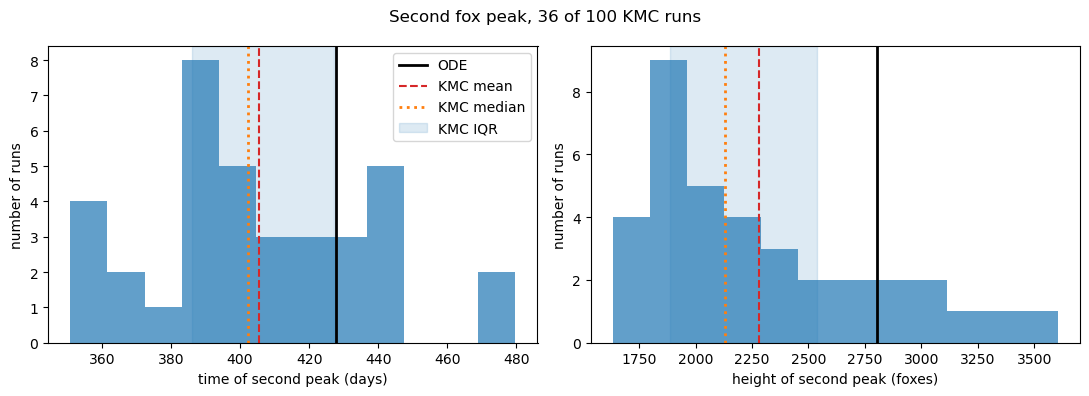

In [7]:
fig, (ax_t, ax_h) = plt.subplots(1, 2, figsize=(11, 4))
for ax, column, ode_value, xlabel in [
    (ax_t, 0, t_ode_peak, "time of second peak (days)"),
    (ax_h, 1, F_ode_peak, "height of second peak (foxes)"),
]:
    x = peaks[:, column]
    ax.hist(x, bins=12, color="C0", alpha=0.7)
    ax.axvline(ode_value, color="k", lw=2, label="ODE")
    ax.axvline(x.mean(), color="C3", ls="--", label="KMC mean")
    ax.axvline(np.median(x), color="C1", ls=":", lw=2, label="KMC median")
    ax.axvspan(*np.percentile(x, [25, 75]), color="C0", alpha=0.15, label="KMC IQR")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("number of runs")
ax_t.legend()
fig.suptitle(f"Second fox peak, {len(peaks)} of {n_runs} KMC runs")
plt.tight_layout()
plt.show()

**Why the peaks differ from the ODE, and what the definition gets wrong.** Three
checks: (1) does the depth of a run's trough predict its second peak? (2) what do
ODE cycles look like if they start from a shallower trough? (3) how far is the
definition's raw maximum from the peak of the curve smoothed over 2 days?

lowest foxes in the trough, runs with a second peak: [ 1  1  1  1  1  1  1  1  1  1  1  2  2  2  3  3  3  4  4  4  4  4  4  5
  6  6  7  8  9 10 10 10 11 12 13 14]
correlation of trough minimum with peak time -0.64, with peak height -0.59

ODE cycle through a trough of F foxes:
  F =  1.6: next peak  2802 foxes, 130 days after the trough
  F =    3: next peak  2529 foxes, 128 days after the trough
  F =    5: next peak  2305 foxes, 125 days after the trough
  F =   10: next peak  1996 foxes, 123 days after the trough
  F =   20: next peak  1682 foxes, 120 days after the trough

raw maximum minus smoothed maximum: height +12.7 foxes on average (+7 to +22), time up to 3.6 days off


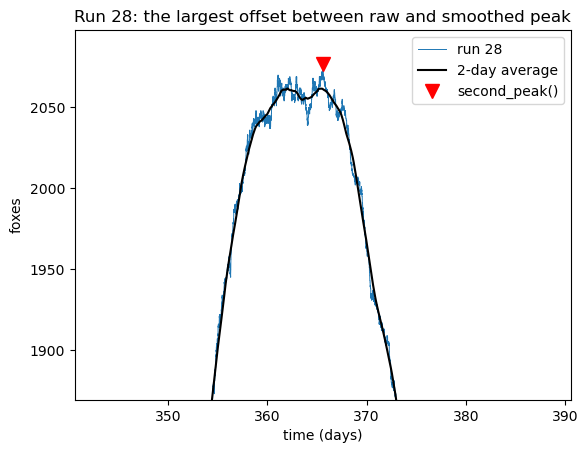

In [8]:
# (1) The lowest number of foxes in the trough, for the runs with a second peak
trough_min = np.array([
    foxes[(times > 150) & (times < p[0])].min()
    for (times, rabbits, foxes), p in zip(trajectories, results) if p is not None
])
print("lowest foxes in the trough, runs with a second peak:", np.sort(trough_min))
print(f"correlation of trough minimum with peak time {np.corrcoef(trough_min, peaks[:, 0])[0, 1]:.2f},"
      f" with peak height {np.corrcoef(trough_min, peaks[:, 1])[0, 1]:.2f}")

# (2) ODE cycles through the fox trough (R = k4/k3 = 100 rabbits) at different depths
print("\nODE cycle through a trough of F foxes:")
t_orbit = np.linspace(0, 300, 30001)
for F_trough in [1.6, 3, 5, 10, 20]:
    orbit = solve_ivp(dydt, (0, 300), [k4 / k3, F_trough], rtol=1e-10, atol=1e-10,
                      dense_output=True)
    F_orbit = orbit.sol(t_orbit)[1]
    print(f"  F = {F_trough:4}: next peak {F_orbit.max():5.0f} foxes, "
          f"{t_orbit[F_orbit.argmax()]:.0f} days after the trough")

# (3) Raw maximum against the maximum of the step function averaged over 2 days
t_grid = np.arange(200, t_end, 0.05)
width = int(2 / 0.05)
offsets = []
for n, ((times, rabbits, foxes), p) in enumerate(zip(trajectories, results)):
    if p is None:
        continue
    f_grid = foxes[np.searchsorted(times, t_grid, side="right") - 1]
    smooth = np.convolve(f_grid, np.ones(width) / width, mode="same")
    j = np.argmax(smooth[width:-width]) + width  # skip the ends, where the average is cut off
    offsets.append((n, p[0] - t_grid[j], p[1] - smooth[j]))
offsets = np.array(offsets)
print(f"\nraw maximum minus smoothed maximum: height {offsets[:, 2].mean():+.1f} foxes on average "
      f"({offsets[:, 2].min():+.0f} to {offsets[:, 2].max():+.0f}), "
      f"time up to {np.abs(offsets[:, 1]).max():.1f} days off")

worst = int(offsets[np.abs(offsets[:, 1]).argmax(), 0])
times, rabbits, foxes = trajectories[worst]
t_peak, height = results[worst]
near = (times > t_peak - 25) & (times < t_peak + 25)
plt.step(times[near], foxes[near], where="post", lw=0.7, label=f"run {worst}")
f_grid = foxes[np.searchsorted(times, t_grid, side="right") - 1]
plt.plot(t_grid, np.convolve(f_grid, np.ones(width) / width, mode="same"), "k",
         label="2-day average")
plt.plot(t_peak, height, "rv", ms=10, label="second_peak()")
plt.xlim(t_peak - 25, t_peak + 25)
plt.ylim(0.9 * height, 1.01 * height)
plt.xlabel("time (days)")
plt.ylabel("foxes")
plt.title(f"Run {worst}: the largest offset between raw and smoothed peak")
plt.legend()
plt.show()

*Answer:*

**Results, 100 runs (seed 3).** There was a second peak in **36 of 100 runs (36%)**.
In the other 64 the foxes died out in the trough, so there was no second peak to
find.

| | mean | median | IQR (25th–75th) | ODE |
|---|---|---|---|---|
| time (days) | 405 | 402 | 386 – 427 | 428 |
| height (foxes) | 2282 | 2129 | 1886 – 2539 | 2804 |

**Compared with the ODE**, the KMC second peak comes about **3 weeks earlier** and is
about **500 foxes lower**. The ODE's time is at the very top of the KMC interquartile
range, and its height is above it. The spread is wide: peaks run from day 351 to 480 and
from 1634 to 3604 foxes, so a few runs peak later or higher than the ODE. But the
mean and median are both clearly earlier and lower, and the mean height is above the
median because the height distribution has a long tail to the right.

**Why they differ.** The second peak only exists in runs whose foxes **survived** the
trough. Those aren't a random sample: they're the runs that got through it. The
depth of the trough sets the next cycle. Lotka–Volterra cycles are closed orbits around
the steady state ($R = k_4/k_3 = 100$, $F = k_1/k_2 = 375$), and the ODE goes around the
outermost one, through 1.6 foxes. A run whose foxes stayed at 5 or 10 in the trough
has been knocked by noise onto a smaller orbit. That orbit is closer to the steady
state, so the cycle has a smaller amplitude and a shorter period. The check above
shows this both ways:

- In the ODE, a cycle through a trough of 5 foxes peaks at 2305 foxes, 125 days after
  the trough. A cycle through 1.6 foxes peaks at 2802, 130 days after.
- In the KMC, runs with a deeper trough had later and higher peaks: the correlation
  of trough minimum with peak time is −0.64, and with height −0.59. The survivors'
  troughs bottomed out between 1 and 14 foxes. In 11 of the 36 runs a single fox was
  left and still recovered. Those 11 include the three latest peaks (days 447–480)
  and the three highest (3142–3604 foxes).

The noise is not just scatter around the ODE answer. It moves the average, because
the deep troughs that give ODE-like peaks are also the ones most likely to kill the
foxes. **The mean second peak is a statistic of survivors only.** It is conditional on
a 36% event and says nothing about the other 64 runs.

**What the definition gets wrong.**

1. **It takes the maximum of a noisy curve, not the top of the cycle.** Near the
   peak the population jitters by about ±10 foxes, and `second_peak` picks the highest
   spike. On average its height is 13 foxes (0.6%) above the peak of a 2-day average,
   and always above it (+7 to +22). Its time is the moment of one lucky birth. In run 28
   (the plot above) the top of the cycle is flat and double-humped from about day 360
   to 367. The definition picks a spike on the second hump at day 365.6, 3.6 days from the
   smoothed peak at day 362, and could just as easily have picked the first. I wouldn't
   call either spike *the* peak: the peak is the whole flat top. These errors are
   small next to the run-to-run spread (standard deviation 33 days and 511 foxes), so
   they don't change the conclusions.
2. **The window is hand-tuned for these rate constants.** "After day 200, more than 5
   days from day 600" works because, here, the first peak has died away to about 10
   foxes by day 200 and every second peak comes by about day 480. A run that came out
   of the trough late would peak after day 595 and be counted as "no peak". If its
   foxes were still rising at day 600, a noise dip just before could make the
   definition pick a point on the rising edge. I looked for these in 400 seeds and
   found none, so it doesn't bite here, but the definition doesn't check that it has
   found a maximum with a rise before it and a fall after it.
3. **It never asks what happened in between.** A run whose foxes died out after day
   250 has a maximum after day 200 of a few foxes, which is under the 100 threshold, so
   it is correctly counted as "no peak". But the threshold of 100 is arbitrary: a cycle
   that recovered to only 90 foxes would be called no peak at all.

## 4. How many runs are enough?

Every number in task 3 came from random runs, so it has its own uncertainty. Repeat
task 3 with 100, 300, 1000 and 3000 trajectories. (Time it first, and work out how
long 3000 will take before you start.)

- How do the mean second-peak time and height change with the number of runs?
- Work out the **standard error** of each mean, $s / \sqrt{n}$, where $s$ is the
  standard deviation and $n$ the number of trajectories with a peak. How does it
  scale with $n$?
- Give the expected time and height of the second peak, and their interquartile
  ranges, to a precision you can justify. Say how you justified it.

In [9]:
def run_set(n_runs, seed):
    """Run n_runs trajectories, keeping only what tasks 4 and 5 need from each.

    Storing every trajectory would take about 0.5 MB per run, so instead this returns
    peaks:      (n_runs, 2) array of second-peak (time, height), NaN where there is none
    foxes_end:  foxes at t_end
    t_extinct:  time the last fox died, NaN if foxes are still alive at t_end
    """
    rng = np.random.default_rng(seed)
    peaks = np.full((n_runs, 2), np.nan)
    foxes_end = np.zeros(n_runs, dtype=int)
    t_extinct = np.full(n_runs, np.nan)
    for n in range(n_runs):
        times, rabbits, foxes = kmc(R0, F0, t_end, rng)
        p = second_peak(times, foxes)
        if p is not None:
            peaks[n] = p
        foxes_end[n] = foxes[np.searchsorted(times, t_end, side="right") - 1]
        if foxes_end[n] == 0:
            t_extinct[n] = times[np.argmax(foxes == 0)]  # zero is absorbing: first zero is the last fox
    return peaks, foxes_end, t_extinct


# Time it first
n_test = 50
start = time.perf_counter()
run_set(n_test, seed=0)
per_run = (time.perf_counter() - start) / n_test
print(f"{per_run * 1000:.0f} ms per run: 3000 runs will take about {3000 * per_run / 60:.1f} min, "
      f"all four sets (4400 runs) about {4400 * per_run / 60:.1f} min")

53 ms per run: 3000 runs will take about 2.7 min, all four sets (4400 runs) about 3.9 min


In [10]:
run_counts = [100, 300, 1000, 3000]
sets = {}
for seed, N in enumerate(run_counts, start=4):  # an independent set of runs for each N
    start = time.perf_counter()
    sets[N] = run_set(N, seed)
    print(f"N = {N:4d}: {time.perf_counter() - start:5.1f} s")

rows = []
for N in run_counts:
    peaks = sets[N][0]
    peaks = peaks[~np.isnan(peaks[:, 0])]
    n = len(peaks)
    p = n / N
    row = {"N": N, "n": n, "p": p, "p_se": np.sqrt(p * (1 - p) / N)}
    for column, name in [(0, "time"), (1, "height")]:
        x = peaks[:, column]
        row[name] = x.mean()
        row[name + "_s"] = x.std(ddof=1)
        row[name + "_se"] = x.std(ddof=1) / np.sqrt(n)
        row[name + "_median"] = np.median(x)
        row[name + "_iqr"] = np.percentile(x, [25, 75])
    rows.append(row)

print(f"\n{'N':>5} {'peaks':>6} {'fraction':>13} | {'mean time':>15} {'s':>5} {'median':>6} "
      f"{'IQR':>13} | {'mean height':>15} {'s':>5} {'median':>6} {'IQR':>11}")
for r in rows:
    print(f"{r['N']:5d} {r['n']:6d} {r['p']:6.3f} ± {r['p_se']:.3f} | "
          f"{r['time']:7.1f} ± {r['time_se']:4.1f} {r['time_s']:5.1f} {r['time_median']:6.1f} "
          f"{r['time_iqr'][0]:5.1f}–{r['time_iqr'][1]:5.1f} | "
          f"{r['height']:7.0f} ± {r['height_se']:4.0f} {r['height_s']:5.0f} {r['height_median']:6.0f} "
          f"{r['height_iqr'][0]:4.0f}–{r['height_iqr'][1]:4.0f}")

N =  100:   5.3 s


N =  300:  16.3 s


N = 1000:  53.5 s


N = 3000: 156.9 s

    N  peaks      fraction |       mean time     s median           IQR |     mean height     s median         IQR
  100     24  0.240 ± 0.043 |   406.0 ±  6.3  30.8  406.3 386.6–423.7 |    2466 ±  149   731   2135 1912–2875
  300    112  0.373 ± 0.028 |   400.9 ±  3.1  32.6  399.8 381.9–421.6 |    2446 ±   59   621   2404 1946–2776
 1000    314  0.314 ± 0.015 |   400.6 ±  1.7  29.3  399.2 379.1–422.7 |    2343 ±   36   638   2232 1883–2726
 3000    992  0.331 ± 0.009 |   400.7 ±  0.9  29.9  399.4 379.4–419.6 |    2383 ±   20   616   2313 1942–2670


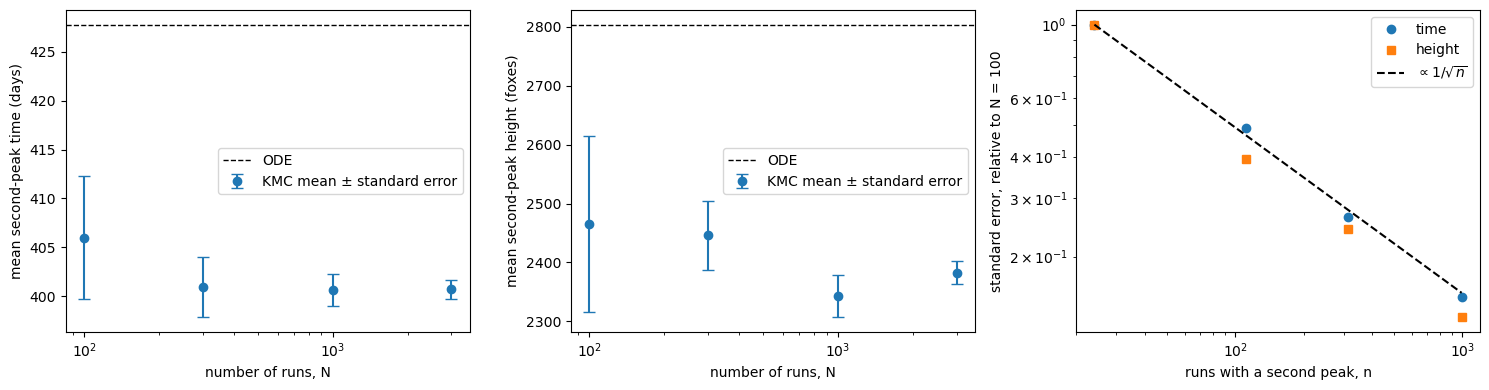

In [11]:
n_peaks = np.array([r["n"] for r in rows])
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, name, ode_value, unit in [(axes[0], "time", t_ode_peak, "days"),
                                  (axes[1], "height", F_ode_peak, "foxes")]:
    ax.errorbar(run_counts, [r[name] for r in rows], yerr=[r[name + "_se"] for r in rows],
                fmt="o", capsize=4, label="KMC mean ± standard error")
    ax.axhline(ode_value, color="k", lw=1, ls="--", label="ODE")
    ax.set_xscale("log")
    ax.set_xlabel("number of runs, N")
    ax.set_ylabel(f"mean second-peak {name} ({unit})")
    ax.legend()

ax = axes[2]
for name, marker in [("time", "o"), ("height", "s")]:
    se = np.array([r[name + "_se"] for r in rows])
    ax.loglog(n_peaks, se / se[0], marker, label=f"{name}")
ax.loglog(n_peaks, np.sqrt(n_peaks[0] / n_peaks), "k--", label=r"$\propto 1/\sqrt{n}$")
ax.set_xlabel("runs with a second peak, n")
ax.set_ylabel("standard error, relative to N = 100")
ax.legend()
plt.tight_layout()
plt.show()

How precisely do we know the interquartile range? The standard error formula is for
a mean, not a percentile, so I estimated it by **bootstrapping**: resample the 3000-run
set's peaks with replacement many times, recompute the percentiles each time, and take
their standard deviation.

In [12]:
peaks_3000 = sets[3000][0]
peaks_3000 = peaks_3000[~np.isnan(peaks_3000[:, 0])]
rng = np.random.default_rng(8)
n_boot = 2000
boot = np.array([
    np.percentile(peaks_3000[rng.integers(0, len(peaks_3000), len(peaks_3000))],
                  [25, 50, 75], axis=0)
    for _ in range(n_boot)
])  # shape (n_boot, 3 percentiles, 2 columns)
for column, name, unit in [(0, "time", "days"), (1, "height", "foxes")]:
    estimate = np.percentile(peaks_3000[:, column], [25, 50, 75])
    spread = boot[:, :, column].std(axis=0)
    print(f"{name:6s}: 25th {estimate[0]:7.1f} ± {spread[0]:4.1f}   median {estimate[1]:7.1f} ± "
          f"{spread[1]:4.1f}   75th {estimate[2]:7.1f} ± {spread[2]:4.1f} {unit}")

time  : 25th   379.4 ±  1.0   median   399.4 ±  1.2   75th   419.6 ±  1.3 days
height: 25th  1942.0 ± 21.3   median  2313.0 ± 24.9   75th  2670.2 ± 32.4 foxes


*Answer:*

**Timing first.** One run takes about 53 ms, so I estimated 2.6 min for 3000 runs and
3.9 min for all four sets (4400 runs). The 3000 actually took 2.6 min. Each $N$ is an
independent set of runs with its own seed, so the four results are four separate
experiments.

**How the means change with the number of runs.** The mean time goes 406 → 401 → 401
→ 401 days, and the mean height 2466 → 2446 → 2343 → 2383 foxes. With 100 runs (only
24 peaks) the means are off by about 5 days and 80 foxes, but every set agrees with
the 3000-run value to within about 1–2 of its own standard errors. That includes
task 3's 100-run set (405 days, 2282 foxes), which is within about 1.2 standard errors.
The means don't drift in one direction as $N$ grows. They scatter less and less around
a fixed value. The **standard deviation** $s$ does not shrink: it stays at about 30
days and 620 foxes for every $N$. It measures the real spread from run to run, which
is a property of the process, not of how many runs we do.

**Standard error.** With $n$ = 24, 112, 314 and 992 peaks, the standard error of the
mean time falls 6.3 → 3.1 → 1.7 → 0.9 days, and of the height 149 → 59 → 36 → 20 foxes.
On the log-log plot these follow the $1/\sqrt{n}$ line. The fitted slopes, from
$n = 24$ to $992$, are $-0.52$ (time) and $-0.54$ (height), against the expected
$-0.5$, since $s$ is constant and the standard error is $s/\sqrt{n}$. So
**halving the error costs four times as many runs**: one more significant figure costs
100 times as many. Only about a third of the runs have a second peak, so for the
peak statistics $n \approx N/3$.

**The answer, from the 3000-run set:**

| | mean | interquartile range |
|---|---|---|
| time of second peak | **401 ± 1 days** | **379 to 420 days** (each end ± 1) |
| height of second peak | **2380 ± 20 foxes** | **1940 to 2670 foxes** (each end ± 20–30) |

There's a second peak in 33.1 ± 0.9% of runs. For comparison, the ODE peaks at day
428 with 2804 foxes, which is 30 standard errors later in time and 21 higher, so the
difference from task 3 is real and not noise.

**How I justified the precision.**

- For the **means** I used the standard error, $s/\sqrt{n}$: 0.9 days and 20 foxes.
  The digits beyond that are noise, so I round the mean time to the nearest day and
  the height to the nearest 10 foxes, and quote the ± so the uncertainty is explicit.
- The ± on the mean is not the spread of the peaks themselves. A single run's peak
  still varies with a standard deviation of about 30 days and 620 foxes, which is
  what the interquartile range describes.
- A **percentile** has no simple $s/\sqrt{n}$ formula. So I **bootstrapped** it:
  resampled the 992 peaks with replacement 2000 times, recomputed the 25th and 75th
  percentiles each time, and took their standard deviation. That gives about ±1 day
  for the time quartiles and ±21 to ±32 foxes for the height quartiles, so the time
  quartiles go to the nearest day and the height quartiles to the nearest 10 foxes.
- The table above is a cross-check. The 1000- and 3000-run sets give quartiles that
  agree to within 1–3 days and 60 foxes, which is consistent with those uncertainties.
  The 100-run sets wander by 5–15 days and 200 foxes.
- All of these uncertainties are for the statistics **as defined** by `second_peak`.
  The definition itself overstates the height by about 13 foxes because it picks a
  noise spike (task 3), a bias comparable to the ±20 standard error that more runs
  would not remove.

## 5. How likely is it that the foxes die out?

From your largest set of runs, what fraction have **no foxes left at day 600**?
That fraction $p$ estimates a probability. Its standard error is
$\sqrt{p(1-p)/N}$ for $N$ runs.

- Give the probability that the foxes die out before 600 days, with its uncertainty.
- How many runs would you need to know it to within ±1 percentage point? To within
  ±0.1?
- Plot a histogram of the times at which the foxes die out. When does it usually
  happen?

In [13]:
peaks, foxes_end, t_extinct = sets[3000]
N = len(foxes_end)
extinct = foxes_end == 0
p = extinct.mean()
p_se = np.sqrt(p * (1 - p) / N)
print(f"foxes extinct by day {t_end} in {extinct.sum()} of {N} runs: p = {p:.3f} ± {p_se:.3f}")
print(f"95% confidence interval (± 1.96 SE): {p - 1.96 * p_se:.3f} to {p + 1.96 * p_se:.3f}")

print("\nthe same from the smaller sets:")
for n_runs in run_counts:
    q = (sets[n_runs][1] == 0).mean()
    print(f"  N = {n_runs:4d}: p = {q:.3f} ± {np.sqrt(q * (1 - q) / n_runs):.3f}")

# Runs needed so that sqrt(p (1 - p) / N) is a given size
print("\nruns needed (using p = {:.3f}):".format(p))
for target in [0.01, 0.001]:
    n_se = p * (1 - p) / target**2
    n_95 = p * (1 - p) * (1.96 / target) ** 2
    print(f"  ± {target * 100:.1f} percentage point: SE = {target} needs {n_se:,.0f} runs; "
          f"95% interval ± {target} needs {n_95:,.0f} runs "
          f"(about {n_95 * per_run / 3600:.1f} h at {per_run * 1000:.0f} ms/run)")

# When the foxes die out, and whether the run had a second peak first
had_peak = ~np.isnan(peaks[:, 0])
t_dead = t_extinct[extinct]
print(f"\nextinction times: median day {np.median(t_dead):.0f}, IQR day "
      f"{np.percentile(t_dead, 25):.0f} to {np.percentile(t_dead, 75):.0f}, "
      f"range day {t_dead.min():.0f} to {t_dead.max():.0f}")
print(f"extinct with no second peak (first trough): {(extinct & ~had_peak).sum()}")
print(f"extinct after a second peak (second trough): {(extinct & had_peak).sum()}")
print(f"alive at day {t_end} with no second peak:      {(~extinct & ~had_peak).sum()}")
print(f"alive at day {t_end} after a second peak:      {(~extinct & had_peak).sum()}")

foxes extinct by day 600 in 2053 of 3000 runs: p = 0.684 ± 0.008
95% confidence interval (± 1.96 SE): 0.668 to 0.701

the same from the smaller sets:
  N =  100: p = 0.760 ± 0.043
  N =  300: p = 0.640 ± 0.028
  N = 1000: p = 0.700 ± 0.014
  N = 3000: p = 0.684 ± 0.008

runs needed (using p = 0.684):
  ± 1.0 percentage point: SE = 0.01 needs 2,160 runs; 95% interval ± 0.01 needs 8,299 runs (about 0.1 h at 53 ms/run)
  ± 0.1 percentage point: SE = 0.001 needs 216,021 runs; 95% interval ± 0.001 needs 829,867 runs (about 12.3 h at 53 ms/run)

extinction times: median day 269, IQR day 248 to 296, range day 195 to 600
extinct with no second peak (first trough): 2008
extinct after a second peak (second trough): 45
alive at day 600 with no second peak:      0
alive at day 600 after a second peak:      947


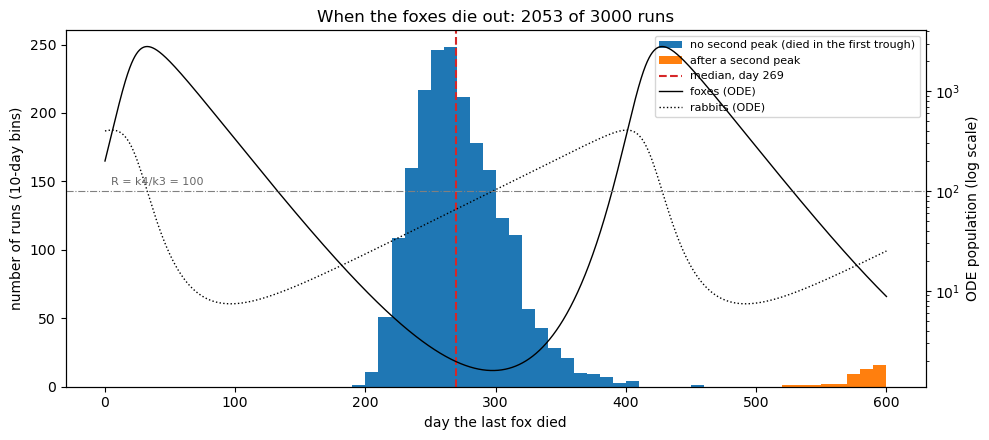

In [14]:
fig, ax = plt.subplots(figsize=(10, 4.5))
bins = np.arange(0, t_end + 10, 10)
ax.hist([t_extinct[extinct & ~had_peak], t_extinct[extinct & had_peak]], bins=bins,
        stacked=True, color=["C0", "C1"],
        label=["no second peak (died in the first trough)", "after a second peak"])
ax.axvline(np.median(t_dead), color="C3", ls="--", label=f"median, day {np.median(t_dead):.0f}")
ax.set_xlabel("day the last fox died")
ax.set_ylabel("number of runs (10-day bins)")
ax.set_title(f"When the foxes die out: {extinct.sum()} of {N} runs")

ax_ode = ax.twinx()
ax_ode.semilogy(t_ode, F_ode, "k", lw=1, label="foxes (ODE)")
ax_ode.semilogy(t_ode, R_ode, "k:", lw=1, label="rabbits (ODE)")
ax_ode.axhline(k4 / k3, color="0.5", lw=0.8, ls="-.")
ax_ode.text(5, k4 / k3 * 1.15, "R = k4/k3 = 100", color="0.4", fontsize=8)
ax_ode.set_ylabel("ODE population (log scale)")
lines = ax.get_legend_handles_labels()
lines_ode = ax_ode.get_legend_handles_labels()
ax.legend(lines[0] + lines_ode[0], lines[1] + lines_ode[1], loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

*Answer:*

**The probability.** In the 3000-run set, the foxes were extinct by day 600 in 2053
runs, so

$$p = 0.684 \pm 0.008 \qquad \left(\text{SE} = \sqrt{p(1-p)/N} = \sqrt{0.684 \times 0.316 / 3000}\right)$$

**The foxes die out within 600 days in 68.4 ± 0.8% of runs** (95% confidence
interval 66.8–70.1%). The smaller sets (76 ± 4%, 64 ± 3%, 70 ± 1%) scatter around
this value by about their own standard errors, the same pattern as the means in
task 4. The ODE says the probability is zero.

**Runs needed.** The standard error is $\sqrt{p(1-p)/N}$, so
$N = p(1-p)/\text{SE}^2$. With $p \approx 0.68$:

| precision | SE = target | 95% interval = ± target ($N = 1.96^2\,p(1-p)/\text{target}^2$) |
|---|---|---|
| ± 1 percentage point | **about 2,200 runs** (2 min) | about 8,300 runs (7 min) |
| ± 0.1 percentage point | **about 216,000 runs** (3 h) | about 830,000 runs (12 h) |

Taking "to within ±1 point" as one standard error, our 3000 runs already do it
(±0.8). Ten times the precision costs **100 times** the runs, because the error falls
as $1/\sqrt{N}$. The ±0.1 point case would need a batch job on Explorer (stretch
problem (b)), or a faster `kmc`. The required $N$ depends on $p$ itself through
$p(1-p)$, which is largest at $p = 0.5$. Near 0.68 it's 0.22, so a rough $p$ is good
enough for planning.

**When the foxes die out.** The histogram has two groups:

- **The first trough: 2008 of the 2053 extinctions (98%).** These runs never had a
  second peak. The last fox died between about day 200 and 400, with a **median of
  day 269 and an IQR of days 248–296**. That is on the falling side of the ODE's fox
  trough, centred a month before its minimum of 1.6 foxes at day 298. This is the
  pattern from task 2, now with 2000 runs: the dangerous time is when the foxes
  are down to a handful **and** the rabbits are still below $k_4/k_3 = 100$, so
  each fox is more likely to die than to breed. After about day 300 the rabbits pass
  100, surviving foxes start to multiply, and extinctions tail off. A small tail out
  to about day 450 comes from runs whose rabbits lagged behind or whose foxes
  lingered at a few individuals.
- **The second trough: 45 extinctions (2%), all after day 520.** These runs survived
  the first trough, had a second peak, and are now heading into the next trough. The
  number per bin is still rising at day 600.

Every run that was alive at day 600 had had a second peak (947 runs). So the
"probability that the foxes die out before 600 days" depends on the cut-off. Day 600
falls partway into the second trough, which the ODE puts at about day 690. With a
longer simulation, many of the 947 survivors would die out there too, and $p$ would
keep rising with every cycle. In the long run the foxes are almost certain to die
out. **68% is the chance it happens within the first cycle and a bit**, not an
overall survival probability.

## 6. Your project

One paragraph. Is there any part of your project where the numbers are small
enough, or the events discrete and random enough, that a continuum model (an ODE or
a PDE) could mislead you, the way the ODE does about the foxes? Think about
molecules on a surface, cells, bubbles, particles, defects, failures. If there is,
what would the "events" and their rates be? If there isn't, why is a continuum model
good enough?

*Answer:*

My project is on lithium-ion battery degradation. Here a continuum model is fine for
the **average** fade but could mislead me about **failure**, much as the ODE does
about the foxes. Capacity fade from the growth of the solid–electrolyte interphase
(SEI) involves about $10^{22}$ lithium ions in a typical 3 Ah cell, so an ODE or PDE (an
SEI thickness growing like $\sqrt{t}$, or a pseudo-2D electrode model) averages over
enormous numbers and the noise is negligible, just as KMC matched the ODE at the first
fox peak. But the processes that end a cell's life suddenly are rare, local and
discrete: lithium plating nucleating at one spot, at a rate that rises steeply once the
local overpotential goes negative during fast charging or at low temperature
(Butler–Volmer kinetics); a dendrite growing through the separator and causing an
internal short; a single electrode particle cracking, at a rate that depends on the
diffusion-induced stress in that particle and on the number of cycles; or a particle
losing electrical contact and dropping out.
Each of these could be a KMC event, with a rate set by the local state (overpotential,
temperature, stress, state of charge). A continuum model gives each cell the same
smooth, average fade curve. It can't produce the spread from cell to cell, or the
small fraction of cells that fail early because one nucleation event happened in the
wrong place, in the same way the ODE couldn't produce 68% of fox populations dying
out. For that I'd need a stochastic model: KMC for the events at the particle or
surface scale, or at least a probabilistic failure model layered on the continuum
fade.

## Stretch problems

**(a) Faster.** Time one trajectory. Then find where the time goes (`%prun`, or
time the pieces). Try Python's `random.random()` in place of `rng.random()`,
appending to lists versus filling a preallocated array, and recording only every
100th event. How much faster can you make it?

**(b) Bigger, on Explorer.** The `.py` paired with this notebook is a script.
Make a copy that runs 10,000 trajectories and saves the second-peak times and heights
and the extinction times with `np.savetxt`, and run it as a batch job on Explorer,
as in Lecture 9. Do your answers to tasks 4 and 5 hold up?

**(c) Is the random clock worth it?** Wikipedia notes that advancing the clock by
$\Delta t = 1/Q_k$ every step, instead of an exponentially distributed $\Delta t$, gives
"the same *average* time scale" (and that note is marked *citation needed*). Test it.
Make a copy of your `kmc` function that uses $\Delta t = 1/Q$, and run both versions
many times. Compare the probability that the foxes die out by day 600, the fraction of
runs with a second peak, and the mean time and height of that peak, each with its
standard error. Which differences are bigger than their uncertainty? How many runs did
you need before you could tell? (Several thousand of each; (a) and (b) help.) Why might
some quantities change and others not?

---

### When you're done

Restart & Run All. Check that every cell ran, in order, with no errors. Commit and
push. Then check on GitHub that your fork shows your latest commit, and that the
notebook displays with its plots.